# Portfolio Optimization with Mean-Variance Analysis

This project builds a diversified portfolio of 8 ETFs (equities, bonds, gold, real estate) using modern portfolio theory. Status: complete.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

## Data: adjusted daily closing prices for 8 ETFs (2015-2025)

In [2]:
tickers = ["SPY", "EFA", "EEM", "IEF", "TLT", "LQD", "GLD", "VNQ"]
start_date = "2015-01-01"
end_date = "2026-01-01"
data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True)
prices = data["Close"]
prices.head()

[*********************100%***********************]  8 of 8 completed


Ticker,EEM,EFA,GLD,IEF,LQD,SPY,TLT,VNQ
Date,,,,,,,,
2015-01-02,30.198095,43.098618,114.080002,81.462944,79.104065,169.267517,91.566429,51.642826
2015-01-05,29.660650,42.081268,115.800003,81.959969,79.427505,166.210632,93.004852,51.925495
2015-01-06,29.536020,41.604603,117.120003,82.510605,79.750999,164.645081,94.680519,52.440536
2015-01-07,30.174717,42.067047,116.430000,82.495239,79.856606,166.696732,94.493530,53.244480
2015-01-08,30.688803,42.636185,115.940002,82.158783,79.599213,169.654755,93.242165,53.445496


In [3]:
# Data checks: dimensions, missing values, first and last dates
print(prices.shape)
print(prices.isna().sum())
print(prices.index[0], prices.index[-1])

(2766, 8)
Ticker
EEM    0
EFA    0
GLD    0
IEF    0
LQD    0
SPY    0
TLT    0
VNQ    0
dtype: int64
2015-01-02 00:00:00 2025-12-31 00:00:00


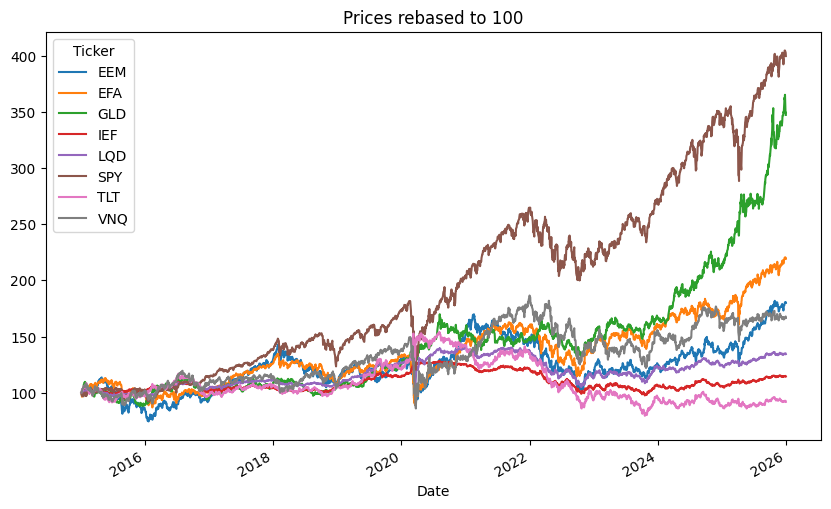

In [4]:
prices_base100 = prices / prices.iloc[0] * 100
prices_base100.plot(figsize=(10,6), title="Prices rebased to 100")
plt.show()

## Step 1: Daily returns and annualized statistics

In [5]:
# Daily simple return: (today's price - yesterday's price) / yesterday's price
returns = prices.pct_change()

# The first day has no previous price, so its row is empty (NaN): drop it
returns = returns.dropna()

print(returns.shape)
returns.head()

(2765, 8)


Ticker,EEM,EFA,GLD,IEF,LQD,SPY,TLT,VNQ
Date,,,,,,,,
2015-01-05,-0.017797,-0.023605,0.015077,0.006101,0.004089,-0.018059,0.015709,0.005474
2015-01-06,-0.004202,-0.011327,0.011399,0.006718,0.004073,-0.009419,0.018017,0.009919
2015-01-07,0.021624,0.011115,-0.005891,-0.000186,0.001324,0.012461,-0.001975,0.015331
2015-01-08,0.017037,0.013529,-0.004209,-0.004078,-0.003223,0.017745,-0.013243,0.003775
2015-01-09,-0.003299,-0.004839,0.011385,0.004934,0.002653,-0.008014,0.010953,0.000470


In [6]:
trading_days = 252  # approximate number of trading days in a year

# Annualize the mean daily return and the daily volatility
mean_annual = returns.mean() * trading_days
vol_annual = returns.std() * np.sqrt(trading_days)

stats = pd.DataFrame({"Annual return": mean_annual,
                      "Annual volatility": vol_annual})
stats.round(4)

,Annual return,Annual volatility
Ticker,,
EEM,0.0746,0.2042
EFA,0.0865,0.1721
GLD,0.1244,0.1475
IEF,0.0146,0.0663
LQD,0.0306,0.0845
SPY,0.1422,0.1779
TLT,0.0037,0.1504
VNQ,0.0678,0.2051


### Interpretation

Over 2015-2025, risk and return are not aligned across the eight ETFs. VNQ (US real estate) is the most volatile asset (20.5%) but returns only 6.8% per year, while SPY (US equities) returns 14.2% with lower volatility (17.8%). Taking more risk was not rewarded.

The bond ETFs illustrate interest rate risk. IEF (7-10 year Treasuries) is the least volatile asset (6.6%), whereas TLT (20+ year Treasuries) shows a volatility close to equities (15.0%) for an almost zero return (0.4%). When the Federal Reserve raised rates sharply in 2022, bond prices fell, and long-maturity bonds fell the most because of their higher duration.

Volatility alone is therefore not enough to compare assets. Return must be measured per unit of risk, and the way assets move together must be analysed, since this drives portfolio risk (Step 2: covariance and correlation).

Note: annual returns are arithmetic means of daily returns multiplied by 252.

In [7]:
# Return per unit of risk: how much return each asset delivers for 1% of volatility
stats["Return / Volatility"] = mean_annual / vol_annual
stats.round(4)

,Annual return,Annual volatility,Return / Volatility
Ticker,,,
EEM,0.0746,0.2042,0.3655
EFA,0.0865,0.1721,0.5026
GLD,0.1244,0.1475,0.8436
IEF,0.0146,0.0663,0.2200
LQD,0.0306,0.0845,0.3616
SPY,0.1422,0.1779,0.7991
TLT,0.0037,0.1504,0.0245
VNQ,0.0678,0.2051,0.3305


In [8]:
# Rank assets by return per unit of risk, from best to worst
stats_sorted = stats.sort_values("Return / Volatility", ascending=False)
stats_sorted.round(4)

,Annual return,Annual volatility,Return / Volatility
Ticker,,,
GLD,0.1244,0.1475,0.8436
SPY,0.1422,0.1779,0.7991
EFA,0.0865,0.1721,0.5026
EEM,0.0746,0.2042,0.3655
LQD,0.0306,0.0845,0.3616
VNQ,0.0678,0.2051,0.3305
IEF,0.0146,0.0663,0.2200
TLT,0.0037,0.1504,0.0245


GLD has the best return per unit of risk (0.84) and TLT the worst (0.02). This changes the ranking based on returns alone: SPY loses first place to gold, which achieves a slightly lower return with lower volatility. EEM and LQD have almost the same ratio (0.37 and 0.36), although EEM is more than twice as risky as LQD.

This gap reflects two differences. First, LQD holds investment-grade US corporate bonds: bondholders receive fixed coupons and are repaid before shareholders in case of bankruptcy, while EEM holds equities, which absorb losses first. Second, emerging markets carry specific risks: political instability, currency depreciation against the US dollar, and a strong dependence on foreign capital, which tends to leave when US interest rates rise, making it harder and more expensive for local companies to refinance their debt.

## Step 2: Covariance and correlation matrices

In [9]:
# Annualized covariance matrix
cov_annual = returns.cov() * trading_days

# Correlation matrix (between -1 and 1)
corr = returns.corr()
corr.round(2)

Ticker,EEM,EFA,GLD,IEF,LQD,SPY,TLT,VNQ
Ticker,,,,,,,,
EEM,1.00,0.83,0.17,-0.12,0.24,0.75,-0.14,0.55
EFA,0.83,1.00,0.14,-0.12,0.28,0.85,-0.16,0.66
GLD,0.17,0.14,1.00,0.35,0.31,0.04,0.28,0.13
IEF,-0.12,-0.12,0.35,1.00,0.72,-0.16,0.92,0.08
LQD,0.24,0.28,0.31,0.72,1.00,0.27,0.70,0.39
SPY,0.75,0.85,0.04,-0.16,0.27,1.00,-0.18,0.72
TLT,-0.14,-0.16,0.28,0.92,0.70,-0.18,1.00,0.03
VNQ,0.55,0.66,0.13,0.08,0.39,0.72,0.03,1.00


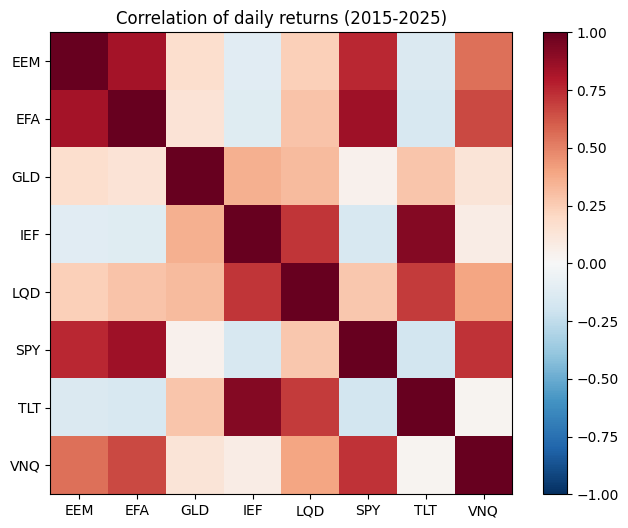

In [10]:
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns)
plt.yticks(range(len(corr)), corr.columns)
plt.title("Correlation of daily returns (2015-2025)")
plt.show()

### Interpretation

IEF and TLT are the most correlated pair (0.92): both are US Treasury funds and react to the same interest rate movements. Equity ETFs also move closely together, such as SPY and EFA (0.85) or EFA and EEM (0.83), since global stock markets follow the same economic cycle. At the other end, SPY is slightly negatively correlated with Treasuries (-0.18 with TLT, -0.16 with IEF) and almost uncorrelated with gold (0.04).

Treasuries are therefore the best diversifiers of US equities over the period: when stocks fall, investors tend to buy government bonds, which pushes their prices up. Gold diversifies in a different way, as it moves almost independently from equities. This average hides an important exception: in 2022, stocks and bonds fell together because inflation forced the Federal Reserve to raise rates, so the negative correlation disappeared exactly when it was needed.

## Step 3: Portfolio return and volatility

In [11]:
def port_return(w, mean):
    return np.dot(w, mean)

def port_vol(w, cov):
    return np.sqrt(np.dot(w, np.dot(cov, w)))

n = len(returns.columns)

# Equal-weight portfolio: 12.5% in each ETF
w_equal = np.ones(n) / n

print("Return:", round(port_return(w_equal, mean_annual), 4))
print("Volatility:", round(port_vol(w_equal, cov_annual), 4))
print("Average volatility of the 8 ETFs:", round(vol_annual.mean(), 4))

Return: 0.068
Volatility: 0.0981
Average volatility of the 8 ETFs: 0.151


### Interpretation

The equal-weight portfolio returns 6.8% per year, exactly the average return of the eight ETFs, but its volatility (9.8%) is far below their average volatility (15.1%). The return of a portfolio is a weighted average of the asset returns, whereas its volatility also depends on correlations: as long as assets are not perfectly correlated, part of their movements offset each other. This diversification effect is why the covariance matrix matters as much as individual volatilities.

## Step 4: Random portfolio simulation

In [12]:
risk_free = 0.02   # assumed risk-free rate
np.random.seed(42)

results = []
for i in range(10000):
    w = np.random.random(n)
    w = w / np.sum(w)   # weights sum to 1
    results.append([port_return(w, mean_annual), port_vol(w, cov_annual)])

portfolios = pd.DataFrame(results, columns=["Return", "Volatility"])
portfolios["Sharpe"] = (portfolios["Return"] - risk_free) / portfolios["Volatility"]
portfolios.describe().round(4)

,Return,Volatility,Sharpe
count,10000.0000,10000.0000,10000.0000
mean,0.0679,0.1010,0.4739
std,0.0101,0.0114,0.0854
min,0.0283,0.0724,0.0960
25%,0.0611,0.0930,0.4174
50%,0.0678,0.0998,0.4761
75%,0.0746,0.1077,0.5314
max,0.1023,0.1571,0.7891


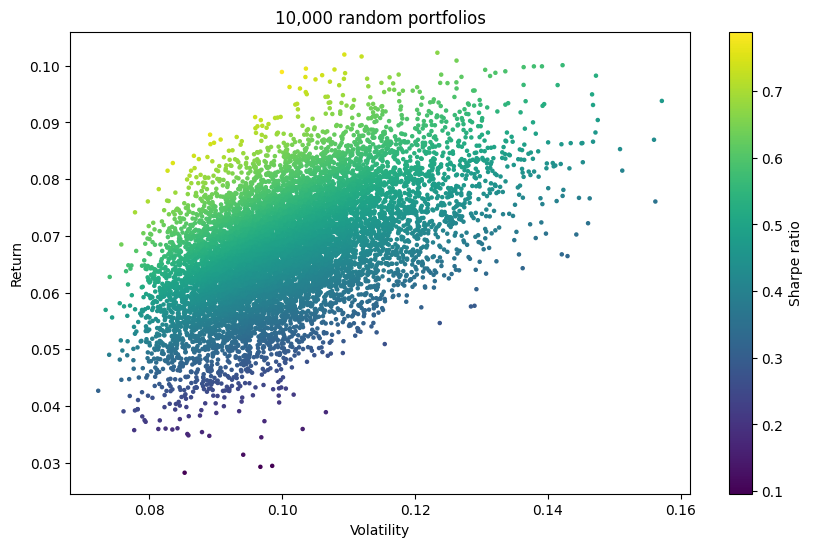

In [13]:
plt.figure(figsize=(10, 6))
plt.scatter(portfolios["Volatility"], portfolios["Return"], c=portfolios["Sharpe"], s=5)
plt.colorbar(label="Sharpe ratio")
plt.xlabel("Volatility")
plt.ylabel("Return")
plt.title("10,000 random portfolios")
plt.show()

### Interpretation

Each point is one of the 10,000 random portfolios. The upper edge of the cloud gathers the portfolios with the highest return for a given level of volatility: it approximates the efficient frontier, and a rational investor would only choose portfolios on this edge. The upper left corner is empty because no combination of these eight ETFs delivers a high return with very low volatility: the least risky assets (IEF, LQD) also have the lowest returns.

The simulation has a limit: random weights rarely produce concentrated portfolios, so the best simulated Sharpe ratio (0.79) stays well below the optimum found in Step 5 (0.97).

## Step 5: Minimum variance and maximum Sharpe ratio portfolios

In [14]:
from scipy.optimize import minimize

def neg_sharpe(w, mean, cov):
    return -(port_return(w, mean) - risk_free) / port_vol(w, cov)

def sum_to_one(w):
    return np.sum(w) - 1

bounds = [(0, 1)] * n   # no short selling
constraints = {"type": "eq", "fun": sum_to_one}

def min_variance(cov):
    res = minimize(port_vol, w_equal, args=(cov,), method="SLSQP", bounds=bounds, constraints=constraints)
    return res.x

def max_sharpe(mean, cov):
    res = minimize(neg_sharpe, w_equal, args=(mean, cov), method="SLSQP", bounds=bounds, constraints=constraints)
    return res.x

w_minvar = min_variance(cov_annual)
w_sharpe = max_sharpe(mean_annual, cov_annual)

weights = pd.DataFrame({"Min variance": w_minvar, "Max Sharpe": w_sharpe}, index=returns.columns)
weights.round(3)

,Min variance,Max Sharpe
Ticker,,
EEM,0.003,0.000
EFA,0.040,0.000
GLD,0.011,0.555
IEF,0.825,0.000
LQD,0.000,0.000
SPY,0.121,0.445
TLT,0.000,0.000
VNQ,0.000,0.000


In [15]:
summary = pd.DataFrame(index=["Min variance", "Max Sharpe", "Equal weight"])
summary["Return"] = [port_return(w, mean_annual) for w in [w_minvar, w_sharpe, w_equal]]
summary["Volatility"] = [port_vol(w, cov_annual) for w in [w_minvar, w_sharpe, w_equal]]
summary["Sharpe"] = (summary["Return"] - risk_free) / summary["Volatility"]
summary.round(4)

,Return,Volatility,Sharpe
Min variance,0.0343,0.0582,0.2461
Max Sharpe,0.1323,0.1164,0.9652
Equal weight,0.0680,0.0981,0.4896


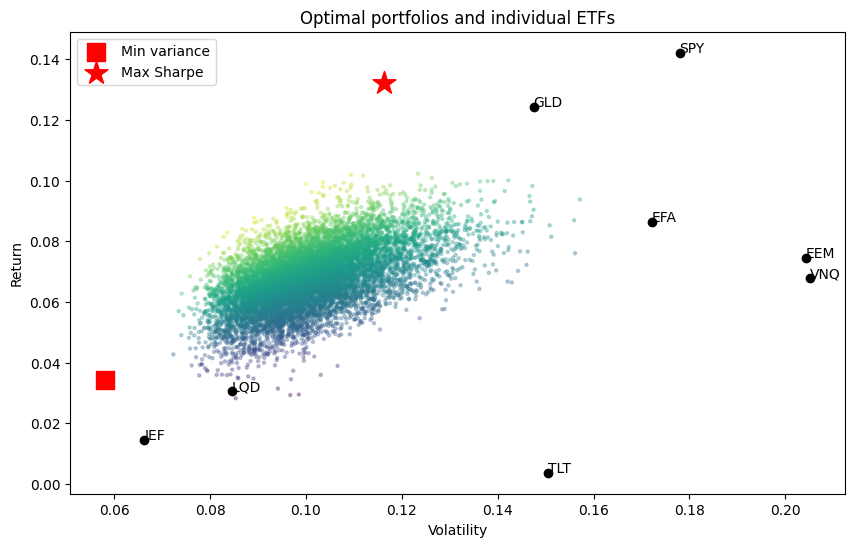

In [16]:
plt.figure(figsize=(10, 6))
plt.scatter(portfolios["Volatility"], portfolios["Return"], c=portfolios["Sharpe"], s=5, alpha=0.3)
plt.scatter(summary.loc["Min variance", "Volatility"], summary.loc["Min variance", "Return"],
            color="red", marker="s", s=150, label="Min variance")
plt.scatter(summary.loc["Max Sharpe", "Volatility"], summary.loc["Max Sharpe", "Return"],
            color="red", marker="*", s=300, label="Max Sharpe")
plt.scatter(vol_annual, mean_annual, color="black")
for ticker in returns.columns:
    plt.annotate(ticker, (vol_annual[ticker], mean_annual[ticker]))
plt.xlabel("Volatility")
plt.ylabel("Return")
plt.title("Optimal portfolios and individual ETFs")
plt.legend()
plt.show()

### Interpretation

The minimum variance portfolio is dominated by IEF (82.5%), the least volatile ETF, with 12.1% in SPY and small positions in EFA, GLD and EEM. Its volatility (5.8%) is lower than that of IEF alone (6.6%), because SPY and IEF are negatively correlated. Its return, however, is only 3.4%.

The maximum Sharpe portfolio holds only two assets: gold (55.5%) and SPY (44.5%). They are the two ETFs with the best return per unit of risk (Step 1), and their correlation is almost zero (0.04), so combining them reduces risk without sacrificing return. The portfolio reaches a Sharpe ratio of 0.97, against 0.49 for the equal-weight portfolio. All other ETFs receive a zero weight because they bring less return for the same risk. Such a concentrated allocation is typical of mean-variance optimization and relies heavily on the past performance of gold and US equities.

## Step 6: Comparison with a benchmark

The weights are estimated on 2015-2020, then tested on 2021-2025, a period the optimization did not use. Weights stay constant and transaction costs are ignored.

In [17]:
train = returns.loc[:"2020-12-31"]
test = returns.loc["2021-01-01":]

mean_train = train.mean() * trading_days
cov_train = train.cov() * trading_days

w_minvar_train = min_variance(cov_train)
w_sharpe_train = max_sharpe(mean_train, cov_train)

pd.DataFrame({"Min variance": w_minvar_train, "Max Sharpe": w_sharpe_train}, index=returns.columns).round(3)

,Min variance,Max Sharpe
Ticker,,
EEM,0.000,0.000
EFA,0.043,0.000
GLD,0.000,0.125
IEF,0.832,0.363
LQD,0.000,0.000
SPY,0.125,0.339
TLT,0.000,0.172
VNQ,0.000,0.000


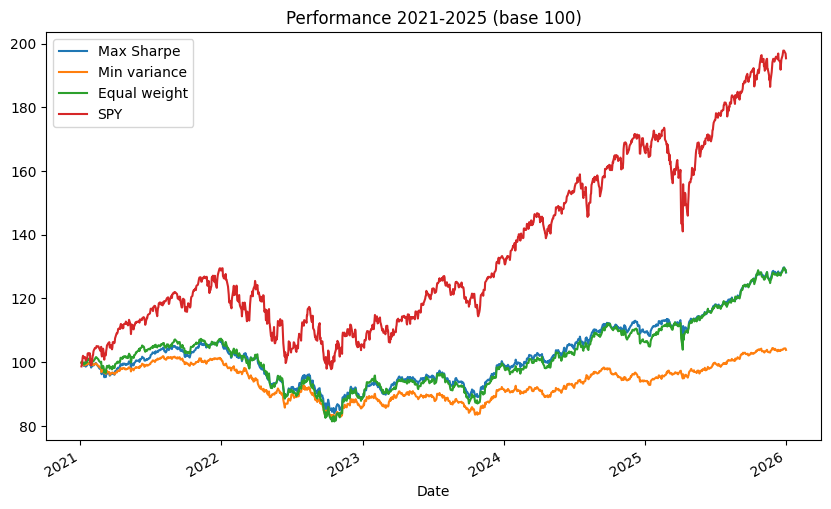

In [18]:
strategies = pd.DataFrame()
strategies["Max Sharpe"] = test.dot(w_sharpe_train)
strategies["Min variance"] = test.dot(w_minvar_train)
strategies["Equal weight"] = test.dot(w_equal)
strategies["SPY"] = test["SPY"]

wealth = (1 + strategies).cumprod() * 100
wealth.plot(figsize=(10, 6), title="Performance 2021-2025 (base 100)")
plt.show()

In [19]:
table = pd.DataFrame()
table["Annual return"] = strategies.mean() * trading_days
table["Annual volatility"] = strategies.std() * np.sqrt(trading_days)
table["Sharpe ratio"] = (table["Annual return"] - risk_free) / table["Annual volatility"]

# Maximum drawdown: largest fall from a previous peak
drawdown = wealth / wealth.cummax() - 1
table["Max drawdown"] = drawdown.min()
table.round(4)

,Annual return,Annual volatility,Sharpe ratio,Max drawdown
Max Sharpe,0.0538,0.0897,0.3765,-0.2148
Min variance,0.0101,0.0719,-0.1378,-0.1948
Equal weight,0.0551,0.1018,0.3453,-0.2422
SPY,0.1491,0.1712,0.7545,-0.2450


### Interpretation

The weights estimated on 2015-2020 are very different from those of Step 5. The maximum Sharpe portfolio now holds 36.3% in IEF and 17.2% in TLT, because Treasuries performed well during that period, and only 12.5% in gold. The minimum variance portfolio is again dominated by IEF (83.2%).

Out of sample, SPY outperformed all three portfolios: it returned 14.9% per year with a Sharpe ratio of 0.75, against 5.4% and 0.38 for the maximum Sharpe portfolio and 5.5% and 0.35 for the equal-weight portfolio. The minimum variance portfolio returned only 1.0% per year, below the risk-free rate, hence a negative Sharpe ratio (-0.14).

Diversification also failed to limit losses. The minimum variance portfolio, despite the lowest volatility (7.2%), suffered a maximum drawdown of -19.5%, close to SPY (-24.5%) and the equal-weight portfolio (-24.2%). The main reason is 2022: the Federal Reserve raised rates sharply, Treasuries fell at the same time as equities, and the bond-heavy portfolios lost the protection they were built on.

The test shows that optimal weights depend heavily on the estimation period, and that low volatility does not guarantee small losses when correlations change. Measures of extreme risk such as Value at Risk and Expected Shortfall address this limitation.

## Limitations

- Expected returns estimated from the past are noisy, and the optimization tends to concentrate the weights on a few assets.
- 2015-2020 was a good period for long-term bonds, which fell sharply in 2022 when rates went up.
- Constant risk-free rate, constant weights, no transaction costs.
- Volatility does not capture extreme losses: Value at Risk and Expected Shortfall do (next project).